### Imports

I'll be using a lot of different modules. Here are some of them listed:

[Numpy](https://numpy.org/) \
[Matplotlib](https://matplotlib.org/) \
[Astropy](https://www.astropy.org/)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import glob, os
import pandas as pd
from astropy.time import Time
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u


### silence warning, annoying!
import warnings
warnings.filterwarnings("ignore")


### Getting things in order!

In [28]:
### All the w files from every night
# oct16_wfiles = sorted(glob.glob("data/slash/16oct26/oct16_2026_w/w*.fits"))
nov2_wfiles = sorted(glob.glob("data/slash/02nov26/nov02_26_w/w*.fits"))
nov3_wfiles = sorted(glob.glob("data/slash/03nov26/nov03_26_w/w*.fits"))

### also all the regular files
# oct16_files = sorted(glob.glob("data/slash/16oct26/oct16_26/*.fits"))
nov2_files = sorted(glob.glob("data/slash/02nov26/nov02_26/*.fits"))
nov3_files = sorted(glob.glob("data/slash/03nov26/nov03_26/*.fits"))

### Add these lists
wfiles = nov2_wfiles + nov3_wfiles
all_files = nov2_files + nov3_files

In [ ]:
### We have to separate the files by target, since two groups shared one night
### I'll use the RA and DEC of our target
### I'll be using astropy a lot, so look up its documentation whenever necessary!

### Our supernova's position
### astropy has a module, see https://docs.astropy.org/en/stable/api/astropy.coordinates.SkyCoord.html
sn26aaiv = SkyCoord("22:37:05.628 +34:24:35.19", unit=(u.hourangle, u.deg))

aaiv_files = []
for f in wfiles:
    h = fits.getheader(f)
    x, y = WCS(h).world_to_pixel(sn26aaiv)
    if (0 <= x < h["NAXIS1"]) and (0 <= y < h["NAXIS2"]):
        aaiv_files.append(f)

print(len(aaiv_files), "files with our SN")
aaiv_files

29 files with our SN


['data/slash/02nov26/nov02_26_w/wnov02_0025.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0026.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0027.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0028.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0029.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0030.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0031.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0032.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0033.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0034.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0035.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0036.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0037.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0038.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0039.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0040.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0041.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0042.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0043.fits',
 'data/slash/02nov26/nov02_26_w

In [30]:
### We have three different filters, so let's split them!
### all our filters
U_files, B_files, V_files, R_files = [], [], [], []

for f in aaiv_files:
    filt = fits.getheader(f)["FILTER"]
    if filt == "Bessell-U":
        U_files.append(f)
    ### 4 frames had an empty filter header??? 
    ### They're in the same sequence as the B ones, so take B
    elif filt == "Harris-B" or filt == "": 
        B_files.append(f)
    elif filt == "Harris-V":
        V_files.append(f)
    elif filt == "Harris-R":
        R_files.append(f)

print("U:", len(U_files), " B:", len(B_files), " V:", len(V_files), " R:", len(R_files))


U: 6  B: 6  V: 7  R: 10


In [31]:
U_files

['data/slash/02nov26/nov02_26_w/wnov02_0032.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0033.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0034.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0035.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0036.fits',
 'data/slash/02nov26/nov02_26_w/wnov02_0037.fits']

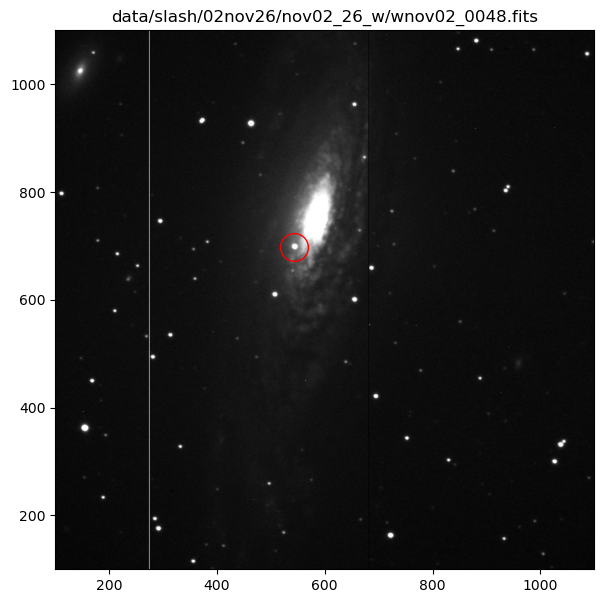

In [41]:
### Let's look at one image and mark where the supernova is
data = fits.getdata(B_files[0])
h = fits.getheader(B_files[0])
x, y = WCS(h).world_to_pixel(sn26aaiv)

plt.figure(figsize=(7, 7))
plt.imshow(data, origin="lower", cmap="gray", vmin=60, vmax=500)
plt.plot(x, y, "o", ms=20, mfc="none", color="red")
plt.title(B_files[0])
plt.xlim(100, 1100)
plt.ylim(100, 1100)
plt.show()


### Now let us start the data processing!

##### 1. Bias reduction

In [43]:
### Let's find our bias files first
### Bias files are called "zero" in the header (0 second exposures)
bias_files = []
for f in all_files:
    if fits.getheader(f)["IMAGETYP"] == "zero":
        bias_files.append(f)

print(len(bias_files), "bias files")
bias_files


12 bias files


['data/slash/03nov26/nov03_26/nov03_0001.fits',
 'data/slash/03nov26/nov03_26/nov03_0002.fits',
 'data/slash/03nov26/nov03_26/nov03_0003.fits',
 'data/slash/03nov26/nov03_26/nov03_0004.fits',
 'data/slash/03nov26/nov03_26/nov03_0005.fits',
 'data/slash/03nov26/nov03_26/nov03_0006.fits',
 'data/slash/03nov26/nov03_26/nov03_0007.fits',
 'data/slash/03nov26/nov03_26/nov03_0008.fits',
 'data/slash/03nov26/nov03_26/nov03_0009.fits',
 'data/slash/03nov26/nov03_26/nov03_0010.fits',
 'data/slash/03nov26/nov03_26/nov03_0011.fits',
 'data/slash/03nov26/nov03_26/nov03_0012.fits']

In [44]:
### combining them into a master bias (same as the SN lab)
bias_frames = []
for f in bias_files:
    bias_frames.append(fits.getdata(f))
bias_frames = np.array(bias_frames)
print(bias_frames.shape)

### Median combine them
master_bias = np.median(bias_frames, axis=0)
print("master bias median:", np.median(master_bias))

(12, 1365, 1365)
master bias median: 2.592987


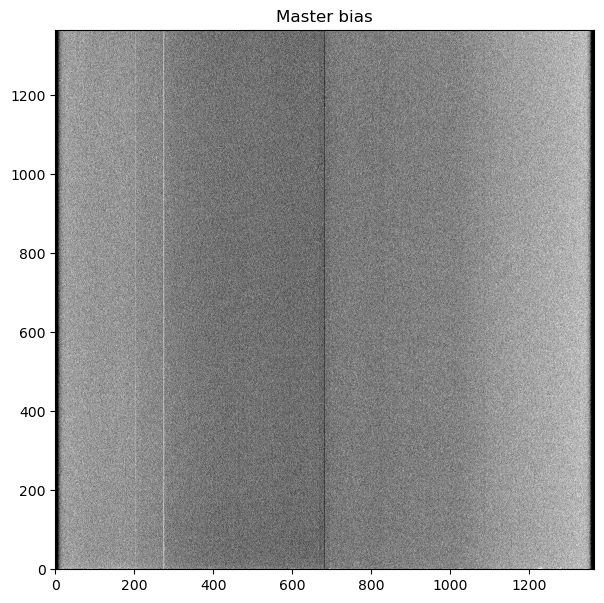

In [55]:
### See the master bias
plt.figure(figsize=(7, 7))
plt.imshow(master_bias, origin="lower", cmap="gray", vmin=0, vmax=5)
plt.title("Master bias")
plt.show()

##### 2. Dark current

In [48]:
### Dark files from the header (skip wdon.fits)
dark_files = []
for f in all_files:
    if fits.getheader(f)["IMAGETYP"] == "dark" and "wdon" not in f:
        dark_files.append(f)

print(len(dark_files), "dark files")
dark_files

5 dark files


['data/slash/02nov26/nov02_26/nov02_0002.fits',
 'data/slash/02nov26/nov02_26/nov02_0003.fits',
 'data/slash/02nov26/nov02_26/nov02_0004.fits',
 'data/slash/02nov26/nov02_26/nov02_0005.fits',
 'data/slash/02nov26/nov02_26/nov02_0006.fits']

In [50]:
### Read all the dark frames into one array
dark_frames = []
for f in dark_files:
    dark_frames.append(fits.getdata(f))
dark_frames = np.array(dark_frames)
print(dark_frames.shape)

### Median combine them
master_dark = np.median(dark_frames, axis=0)

### A dark also has the bias, so take it out,
### then divide by the exposure time to get counts per second
### similar steps to the lab notebooks, check them out
dark_exptime = fits.getheader(dark_files[0])["EXPTIME"]
dark_rate = (master_dark - master_bias) / dark_exptime

print("dark exposure time:", dark_exptime, "s")
print("dark current:", np.median(dark_rate), "counts/pixel/s")

(5, 1365, 1365)
dark exposure time: 90.0 s
dark current: 0.027823893 counts/pixel/s


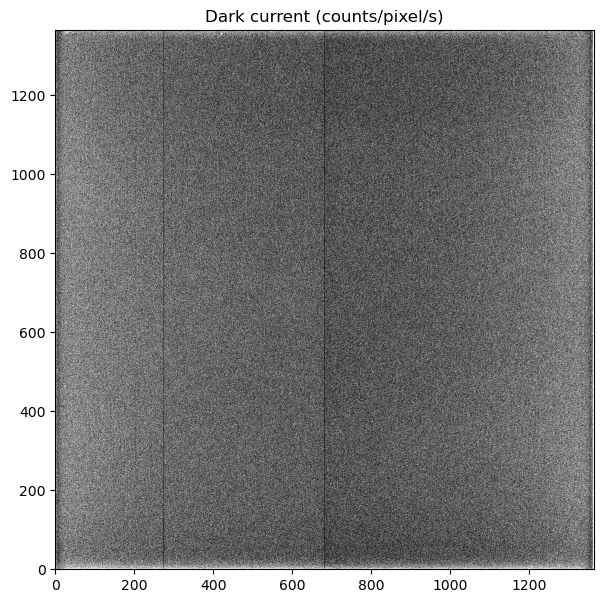

In [56]:
### See the dark current
plt.figure(figsize=(7, 7))
plt.imshow(dark_rate, origin="lower", cmap="gray", vmin=0, vmax=0.07)
plt.title("Dark current (counts/pixel/s)")
plt.show()
